<a href="https://colab.research.google.com/github/letterhill/sketch2popup/blob/feat%2Fseoa-preprocess-v3/06_preprocess_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a href="https://colab.research.google.com/github/letterhill/sketch2popup/blob/feat%2Fseoa-preprocess/notebooks/06_preprocess_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 06. 이미지 전처리 (최종)

위에서부터 차례로 실행하면 됨. Colab 무료 CPU로 8분 정도 걸림.

최종 전처리는 v3 = tophat2 → gate.
- tophat2: 각 픽셀이 주변보다 얼마나 어두운지를 재서 선만 남김. 종이 질감이나 그림자는 빠지고 흰 바탕에 검은 선이 나옴
- gate: bbox 바깥은 흰색으로 지움

`pp.preprocess(img, bbox, mode='v3')`로 부르면 되고, 한 장에 40ms 정도 걸림.

선을 굵게 하는 erode5까지 붙인 `v3_thick`은 대안으로 같이 계산함. 선이 굵어지면 윤곽이 닫혀서 Otsu 분할 점수가 v2만큼 오르는데, 정답 마스크가 실루엣이라서 생기는 효과일 수 있어서 넣을지는 아직 정하지 않음.

이전 최종안 v2(CLAHE → 평탄화 → erode3)는 점수는 좋았지만 눈으로 보면 배경이 지저분했음.

In [2]:
# 1. 설정
from google.colab import drive
drive.mount('/content/drive')
import os, sys, json, time, shutil, unicodedata, warnings, importlib
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings('ignore')

FOLDER = '컴퓨터비전'      # 공유 폴더 이름 (내 드라이브에 바로가기로 추가해 둬야 함)
BASE = None               # 자동으로 못 찾으면 경로를 직접 적음
OK_STATUS = {'ok'}        # 평가에 쓸 검토 결과 ('fix'는 정답이 틀려서 제외)
MARGIN = 0.10             # bbox 바깥 여유 비율
SEED = 0
GROUP_COL = None          # subset_list.csv의 그룹 컬럼 이름 (None이면 자동)
META_ID_COL = None        # subset_list.csv의 이미지 id 컬럼 이름 (None이면 자동)


def nfc(s):
    return unicodedata.normalize('NFC', s)


def find_base(name, roots=('/content/drive/MyDrive', '/content/drive/Shareddrives')):
    # subset/ 폴더가 들어 있는 '컴퓨터비전' 폴더를 찾음
    for root in roots:
        for d, dirs, _ in os.walk(root):
            for x in dirs:
                if nfc(x) == nfc(name) and os.path.isdir(os.path.join(d, x, 'subset')):
                    return os.path.join(d, x)
            if d[len(root):].count('/') >= 1:
                dirs[:] = []
    return None


BASE = BASE or find_base(FOLDER)
assert BASE, f"'{FOLDER}' 폴더를 못 찾음. 공유 폴더 바로가기를 확인"
OUT = os.path.join(BASE, 'results', 'preprocess')
os.makedirs(OUT, exist_ok=True)
np.random.seed(SEED)
print('BASE =', BASE)

Mounted at /content/drive
BASE = /content/drive/MyDrive/컴퓨터비전


## 2. 전처리 모듈
함수는 `preprocess.py`로 따로 둠. 아래 셀이 파일을 만들고, 맨 아래에서 공유 폴더로 복사함. 다른 팀원은 `import preprocess as pp`로 쓰면 됨.
전처리 함수는 입력과 같은 크기의 이미지를 돌려주기 때문에 bbox나 정답 마스크 좌표를 그대로 쓸 수 있음.

In [3]:
%%writefile preprocess.py
"""preprocess.py — 손그림 사진 전처리 모듈 (② 이미지 전처리 담당)

설계 원칙
- 광학 모듈(노이즈 제거, 대비, 조명 균일화, 선 억제)은 gray uint8 HxW -> 같은 크기 gray 를 돌려준다.
  크기와 좌표가 안 바뀌므로 bbox 와 정답 마스크를 그대로 쓸 수 있다.
- 진단(diagnose)은 정답 마스크 없이 이미지만 보고 계산한다 (새 사진에도 쓸 수 있어야 하므로).
- 기하 보정(find_paper_quad / rectify)만 좌표가 바뀌므로 별도 실험에서만 쓴다.

사용 예
    import preprocess as pp
    out = pp.preprocess(img, bbox, mode='v3')      # 최종. 대안은 'v3_thick' (선을 굵게)
    mask = pp.segment(out, bbox, method='otsu')
"""
import cv2
import numpy as np

# ---------------------------------------------------------------- 기본 유틸


def to_gray(img):
    """BGR/RGB 3채널 -> gray. 이미 gray 면 그대로. (RGB 와 BGR 의 gray 차이는 작다)"""
    if img.ndim == 2:
        return img
    if img.shape[2] == 4:
        img = img[:, :, :3]
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


def content_rect(gray, thr=8):
    """검은 여백(letterbox)을 뺀 내용 영역 (x0, y0, x1, y1)."""
    rows = np.where(gray.mean(axis=1) > thr)[0]
    cols = np.where(gray.mean(axis=0) > thr)[0]
    if len(rows) == 0 or len(cols) == 0:
        return 0, 0, gray.shape[1], gray.shape[0]
    return int(cols[0]), int(rows[0]), int(cols[-1]) + 1, int(rows[-1]) + 1


def crop_context(gray, bbox, margin=0.10):
    """bbox 에 margin 만큼 여유를 둔 crop 영역과, 그 안에서 bbox 의 위치.

    반환: (x0, y0, x1, y1) crop 영역(원본 좌표), (bx0, by0, bx1, by1) bbox(crop 좌표)
    여유 영역은 배경(조명·종이) 추정에 쓰고, 분할은 bbox 안에서만 한다.
    """
    x, y, w, h = [float(v) for v in bbox]
    cx0, cy0, cx1, cy1 = content_rect(gray)
    mx, my = w * margin, h * margin
    x0 = int(max(cx0, np.floor(x - mx)))
    y0 = int(max(cy0, np.floor(y - my)))
    x1 = int(min(cx1, np.ceil(x + w + mx)))
    y1 = int(min(cy1, np.ceil(y + h + my)))
    x1, y1 = max(x1, x0 + 16), max(y1, y0 + 16)
    bx0 = int(max(x0, np.floor(x))) - x0
    by0 = int(max(y0, np.floor(y))) - y0
    bx1 = int(min(x1, np.ceil(x + w))) - x0
    by1 = int(min(y1, np.ceil(y + h))) - y0
    bx1, by1 = max(bx1, bx0 + 8), max(by1, by0 + 8)
    return (x0, y0, x1, y1), (bx0, by0, bx1, by1)


def _odd(n):
    n = int(n)
    return n if n % 2 == 1 else n + 1


# ---------------------------------------------------------------- 광학 모듈 (gray -> gray, 크기 유지)


def denoise(g, method='median', k=3):
    if method == 'median':
        return cv2.medianBlur(g, _odd(k))
    if method == 'gauss':
        return cv2.GaussianBlur(g, (_odd(k), _odd(k)), 0)
    if method == 'bilateral':
        return cv2.bilateralFilter(g, 5, 40, 5)
    if method == 'nlm':
        return cv2.fastNlMeansDenoising(g, None, 7, 5, 15)
    raise ValueError(method)


def stretch(g, lo=1, hi=99, gamma=1.0):
    """퍼센타일 대비 늘리기 (어두운 사진). 종이가 hi 로, 잉크가 lo 로 가게 한다."""
    a, b = np.percentile(g, [lo, hi])
    if b - a < 10:
        return g
    x = np.clip((g.astype(np.float32) - a) / (b - a), 0, 1)
    if gamma != 1.0:
        x = x ** gamma
    return (x * 255).astype(np.uint8)


def clahe(g, clip=2.0, tile=8):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(g)


def block_grid(g, grid=8, q=90):
    """블록별 q 퍼센타일 밝기 격자 (종이 밝기 지도의 거친 추정)."""
    h, w = g.shape
    gy, gx = max(2, min(grid, h // 16)), max(2, min(grid, w // 16))
    ys = np.linspace(0, h, gy + 1).astype(int)
    xs = np.linspace(0, w, gx + 1).astype(int)
    pts = np.zeros((gy, gx), np.float32)
    for i in range(gy):
        for j in range(gx):
            pts[i, j] = np.percentile(g[ys[i]:ys[i + 1], xs[j]:xs[j + 1]], q)
    return pts


def estimate_background(g, grid=8, q=90, sigma_frac=0.06, ink_ratio=0.35):
    """배경(종이) 밝기 지도. 블록 퍼센타일 -> (잉크 블록 제외·보간) -> 보간 -> 가우시안 평활.

    ink_ratio: 블록 밝기가 (전체 블록 90% 밝기 x ink_ratio) 보다 어두우면 색칠된 잉크 영역으로 보고
    배경 추정에서 빼고 주변 값으로 채운다. 이게 없으면 색칠이 큰 그림 안쪽이 '어두운 배경'으로 오인되어
    캐릭터가 밝게 번진다. 0 이면 끈다. 그림자는 보통 이보다 덜 어두워서 그대로 보정 대상이 된다.
    """
    h, w = g.shape
    pts = block_grid(g, grid, q)
    if ink_ratio > 0:
        valid = (pts >= ink_ratio * np.percentile(pts, 90)).astype(np.float32)
        if 4 <= valid.sum() < valid.size:
            sig = max(1.0, 0.25 * max(pts.shape))
            num = cv2.GaussianBlur(pts * valid, (0, 0), sig, borderType=cv2.BORDER_REPLICATE)
            den = cv2.GaussianBlur(valid, (0, 0), sig, borderType=cv2.BORDER_REPLICATE)
            pts = np.where(valid > 0, pts, num / np.maximum(den, 1e-3)).astype(np.float32)
    bg = cv2.resize(pts, (w, h), interpolation=cv2.INTER_CUBIC)
    bg = np.clip(bg, pts.min(), pts.max())
    return cv2.GaussianBlur(bg, (0, 0), max(1.0, sigma_frac * min(h, w)))


def flat_block(g, grid=8, q=90, sigma_frac=0.06, floor=20, ink_ratio=0.35):
    """조명 균일화: g / 배경추정 * 255. 색칠이 큰 그림은 ink_ratio 로 잉크 블록을 배경 추정에서 뺀다."""
    bg = estimate_background(g, grid, q, sigma_frac, ink_ratio)
    return np.clip(g / np.maximum(bg, floor) * 255, 0, 255).astype(np.uint8)


def flat_morph(g, size_frac=0.25, scale=4):
    """조명 균일화(비교군): 큰 closing 으로 어두운 잉크를 지운 배경 추정. 1/scale 크기에서 계산."""
    h, w = g.shape
    sm = cv2.resize(g, (max(8, w // scale), max(8, h // scale)), interpolation=cv2.INTER_AREA)
    k = _odd(max(3, size_frac * min(sm.shape)))
    bg = cv2.morphologyEx(sm, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))
    bg = cv2.GaussianBlur(bg, (0, 0), max(1.0, 0.05 * min(sm.shape)))
    bg = cv2.resize(bg, (w, h), interpolation=cv2.INTER_LINEAR).astype(np.float32)
    return np.clip(g / np.maximum(bg, 20) * 255, 0, 255).astype(np.uint8)


def retinex_ssr(g, sigma_frac=0.15):
    """Single-scale Retinex: log(g) - log(큰 가우시안 블러). 조명 균일화(비교군)."""
    s = max(2.0, sigma_frac * min(g.shape))
    f = g.astype(np.float32) + 1.0
    r = np.log(f) - np.log(cv2.GaussianBlur(f, (0, 0), s))
    lo, hi = np.percentile(r, [1, 99.5])
    if hi - lo < 1e-3:
        return g
    return (np.clip((r - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)


def suppress_lines(g, frac=0.25, thick=5, max_tilt_deg=15, inner=None):
    """공책 줄·모눈 같은 '긴 직선'을 배경 밝기로 덮는다.

    캐릭터의 선은 전부 bbox 안에 있으므로, **bbox 바깥(여유 영역)까지 뻗는 직선은 캐릭터가 아니다.**
    - inner(= crop 안에서 bbox 위치)를 주면: 선분의 한쪽 끝이라도 bbox 바깥이면 줄로 본다
    - inner 가 없으면: crop 짧은 변의 50% 이상인 선만 줄로 본다 (덜 안전)
    - 수평/수직에서 max_tilt_deg 이내만
    - 줄이 캐릭터 위를 지나가도 **잉크는 지우지 않는다**: 줄 밝기를 bbox 바깥의 순수한 줄 부분에서
      재서(ref), ref 보다 확실히 어두운 픽셀(= 잉크)과 그 경계 주변은 남기고 줄 밝기대만 배경 밝기로 바꾼다
    ※ 한계: 줄이 선을 이어 주던 윤곽선 그림은 줄을 지우면 끊어져 보일 수 있다 (끊긴 선 연결은 실험 C 몫).
    ※ 배경 잔여 제거(실험 C)와 역할이 겹칠 수 있으니 팀에서 범위를 맞출 것.
    """
    h, w = g.shape
    m = min(h, w)
    bg = estimate_background(g, 8, 90)
    gf = g.astype(np.float32)
    edges = cv2.Canny(cv2.GaussianBlur(g, (3, 3), 0), 40, 120)
    segs = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=max(10, int(0.2 * m)),
                           minLineLength=max(20, int(frac * m)), maxLineGap=max(3, int(0.03 * m)))
    if segs is None:
        return g
    inner_mask = np.zeros((h, w), bool)
    if inner is not None:
        inner_mask[inner[1]:inner[3], inner[0]:inner[2]] = True
    erase = np.zeros((h, w), bool)
    pad = thick + 3
    for x1, y1, x2, y2 in np.asarray(segs).reshape(-1, 4):   # OpenCV 4.x (N,1,4) / 5.x (N,4) 모두 처리
        ang = abs(np.degrees(np.arctan2(y2 - y1, x2 - x1))) % 180
        if min(ang, abs(ang - 90), abs(ang - 180)) > max_tilt_deg:
            continue
        if inner is not None:
            bx0, by0, bx1, by1 = inner
            if (bx0 < x1 < bx1 and by0 < y1 < by1) and (bx0 < x2 < bx1 and by0 < y2 < by1):
                continue                                         # 두 끝이 모두 bbox 안 -> 캐릭터의 일부일 수 있다
        elif np.hypot(x2 - x1, y2 - y1) < 0.5 * m:
            continue
        xa, xb = max(0, min(x1, x2) - pad), min(w, max(x1, x2) + pad + 1)      # 선분 주변 창에서만 계산
        ya, yb = max(0, min(y1, y2) - pad), min(h, max(y1, y2) + pad + 1)
        sm = np.zeros((yb - ya, xb - xa), np.uint8)
        cv2.line(sm, (int(x1 - xa), int(y1 - ya)), (int(x2 - xa), int(y2 - ya)), 255, thick)
        sel = sm > 0
        gw, bgw = gf[ya:yb, xa:xb], bg[ya:yb, xa:xb]
        pure = sel & ~inner_mask[ya:yb, xa:xb]                   # 순수한 줄 픽셀: bbox 바깥에 있는 부분
        ref_px = gw[pure & (gw < 0.9 * bgw)]
        if ref_px.size < 5:
            continue
        ref = float(np.median(ref_px))
        delta = max(15.0, 3.0 * 1.4826 * float(np.median(np.abs(ref_px - ref))))
        ink = (gw < ref - delta).astype(np.uint8)                 # 줄보다 확실히 어두운 것 = 잉크
        near_ink = cv2.dilate(ink, np.ones((5, 5), np.uint8)) > 0   # 잉크 경계의 안티앨리어싱 픽셀도 보호
        erase[ya:yb, xa:xb] |= sel & (gw >= ref - delta) & (gw < 0.9 * bgw) & ~near_ink
    out = g.copy()
    out[erase] = np.clip(bg[erase], 0, 255).astype(np.uint8)
    return out


def erode_dark(g, k=3):
    """어두운 선을 k x k 최소값 필터로 굵게 함. k는 픽셀 단위 (512px 기준 데이터에서 확인)."""
    return cv2.erode(g, np.ones((k, k), np.uint8))


def ink_map(g, ks=(9, 25, 61, 121), gates=(0.0, 0.20, 0.30, 0.38)):
    """주변(closing)보다 얼마나 어두운지를 0~1 비율로 잰 지도 (다중 크기 black top-hat).
    작은 커널은 얇은 선, 큰 커널은 꽉 찬 덩어리를 잡음. 큰 커널은 gates를 넘을 때만 인정해서 넓고 덜 어두운 그림자는 걸러짐.
    커널은 가로세로 500~600px 크롭 기준. 25보다 큰 커널은 절반 해상도에서 계산함."""
    h, w = g.shape
    out = np.zeros((h, w), np.float32)
    for k, gt in zip(ks, gates):
        s = 1 if k <= 25 else 2
        f = g if s == 1 else cv2.resize(g, (max(8, w // 2), max(8, h // 2)), interpolation=cv2.INTER_AREA)
        kk = k if s == 1 else (k // 2) | 1
        P = kk + 9
        f = cv2.copyMakeBorder(f, P, P, P, P, cv2.BORDER_REPLICATE).astype(np.float32)
        C = cv2.morphologyEx(f, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kk, kk)))
        r = np.clip((C - f) / np.maximum(C, 30), 0, 1)[P:-P, P:-P]
        r = np.where(r > gt, r, 0)
        if s == 2:
            r = cv2.resize(r, (w, h), interpolation=cv2.INTER_LINEAR)
        out = np.maximum(out, r)
    return out


def tophat2(g, lo_k=3.0, hi_frac=0.5, min_area=12, bold_pct=90, gam=0.8, border_frac=0.04, gates=(0.0, 0.20, 0.30, 0.38)):
    """ink_map + 이력 임계 + 자동 진하기. 흰 바탕에 검은 선인 같은 크기 gray를 돌려줌.
    low = 안쪽 영역 중앙값 + lo_k * MAD. 약한 선(low 초과)은 강한 선(high 초과)과 이어진 덩어리만 남김.
    high는 선 세기 최댓값의 85%를 넘지 않게 제한 (넘으면 잡음 큰 사진이 통째로 비어 버림).
    선 세기의 bold_pct 분위 값을 검정으로 맞추고, 바깥 border_frac 띠는 0으로 둠."""
    r = ink_map(g, gates=gates)
    bh, bw = max(1, int(border_frac * g.shape[0])), max(1, int(border_frac * g.shape[1]))
    inner = r[bh:-bh, bw:-bw]
    med = np.median(inner)
    mad = np.median(np.abs(inner - med)) * 1.4826            # 잡음 기준은 안쪽에서만 (띠를 0으로 만들기 전에 계산)
    r[:bh, :] = 0; r[-bh:, :] = 0; r[:, :bw] = 0; r[:, -bw:] = 0
    low = med + lo_k * mad
    high = min(max(low * 1.5, hi_frac * np.percentile(r, 99.7)), 0.85 * r.max())
    weak = cv2.morphologyEx((r > low).astype(np.uint8), cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(weak, connectivity=8)
    mx = np.zeros(n, np.float32)
    np.maximum.at(mx, lab.ravel(), r.ravel())
    keep = (mx > high) & (st[:, cv2.CC_STAT_AREA] >= min_area)
    keep[0] = False
    rk = np.where(keep[lab], r, 0)
    pos = rk[rk > 0]
    scale = max(np.percentile(pos, bold_pct), 0.15) if pos.size else 1.0
    return (255 * (1 - np.clip(rk / scale, 0, 1) ** gam)).astype(np.uint8)


def gate_to_bbox(g, inner, pad_frac=0.03):
    """bbox(+pad_frac) 바깥을 흰색으로. 책상이나 사진 모서리가 선으로 남는 것을 막음.
    선이 전부 bbox 안에 있다고 가정하므로, bbox가 헐거우면 pad_frac을 키울 것 (예: 0.05)."""
    x0, y0, x1, y1 = inner
    p = int(pad_frac * max(x1 - x0, y1 - y0))
    out = np.full_like(g, 255)
    ya, yb = max(0, y0 - p), min(g.shape[0], y1 + p)
    xa, xb = max(0, x0 - p), min(g.shape[1], x1 + p)
    out[ya:yb, xa:xb] = g[ya:yb, xa:xb]
    return out


STEPS = {
    'median3': lambda g: denoise(g, 'median', 3),
    'gauss3': lambda g: denoise(g, 'gauss', 3),
    'bilateral': lambda g: denoise(g, 'bilateral'),
    'nlm': lambda g: denoise(g, 'nlm'),
    'stretch': stretch,
    'clahe': clahe,
    'clahe_strong': lambda g: clahe(g, 6.0, 4),     # 05번 노트북에서 정한 강한 CLAHE (clip 6, tile 4)
    'erode3': erode_dark,
    'flat_block': flat_block,
    'flat_morph': flat_morph,
    'retinex': retinex_ssr,
    'lines': suppress_lines,
    'tophat2': tophat2,
    'erode5': lambda g: erode_dark(g, 5),            # v3: 가는 선을 굵게 해서 윤곽을 닫는다 (5x5). 분할기가 안쪽을 채우려면 윤곽이 닫혀 있어야 한다
}


def apply_steps(g, steps, inner=None):
    for s in steps:
        if s == 'lines':
            g = suppress_lines(g, inner=inner)       # bbox 위치를 알아야 캐릭터 선을 지키며 줄을 지울 수 있다
        elif s == 'gate':
            g = gate_to_bbox(g, inner)               # bbox 바깥의 결과를 버린다 (종이 바깥 잔여 제거)
        else:
            g = STEPS[s](g) if isinstance(s, str) else s(g)
    return g


# ---------------------------------------------------------------- 진단 (정답 없이)

DEFAULT_THRESHOLDS = {'dark': 110.0, 'uneven': 0.18, 'busy': 0.06, 'noisy': 3.0}


def estimate_noise(g):
    """Immerkaer 방식 잡음 표준편차 추정 (중앙값 기반이라 에지에 덜 흔들린다)."""
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
    r = cv2.filter2D(g.astype(np.float32), -1, k)[1:-1, 1:-1]
    return float(1.4826 * np.median(np.abs(r)) / 6.0)


def ring_mask(shape, inner):
    """bbox 바깥 여유 영역(링). 너무 얇으면 crop 가장자리 띠로 대체한다."""
    h, w = shape
    bx0, by0, bx1, by1 = inner
    m = np.ones((h, w), bool)
    m[by0:by1, bx0:bx1] = False
    if m.mean() < 0.04:
        m = np.zeros((h, w), bool)
        t = max(2, int(0.08 * min(h, w)))
        m[:t, :] = m[-t:, :] = m[:, :t] = m[:, -t:] = True
    return m


def measure(gc, inner):
    """진단 수치: brightness(종이 밝기), unevenness(조명 불균일), edge_density(배경 에지), noise."""
    pts = block_grid(gc, 8, 90)
    med = float(np.median(pts))
    unev = float((np.percentile(pts, 90) - np.percentile(pts, 10)) / (med + 1e-6))
    ring = ring_mask(gc.shape, inner)
    edges = cv2.Canny(cv2.GaussianBlur(gc, (3, 3), 0), 50, 150) > 0
    return {'brightness': med, 'unevenness': unev,
            'edge_density': float(edges[ring].mean()), 'noise': estimate_noise(gc)}


def flags_from_measures(m, thr=None):
    thr = thr or DEFAULT_THRESHOLDS
    return {'dark': m['brightness'] < thr['dark'],
            'uneven': m['unevenness'] > thr['uneven'],
            'busy': m['edge_density'] > thr['busy'],
            'noisy': m['noise'] > thr['noisy']}


def calibrate_thresholds(measures, q_dark=0.15, q_uneven=0.70, q_busy=0.75, q_noisy=0.80):
    """dev 분포의 분위수로 임계값을 정한다 (정답 라벨 미사용).
    분위수는 데이터 탐색 문서의 그룹 정의(밝기 하위 15%, 편차 상위 30%, 에지 상위 25%)와 맞췄다.
    확정한 임계값(절대값)은 저장해 두고 새 사진에도 그대로 쓴다."""
    return {'dark': float(np.quantile([m['brightness'] for m in measures], q_dark)),
            'uneven': float(np.quantile([m['unevenness'] for m in measures], q_uneven)),
            'busy': float(np.quantile([m['edge_density'] for m in measures], q_busy)),
            'noisy': float(np.quantile([m['noise'] for m in measures], q_noisy))}


def flags_from_group(group):
    """oracle 라우팅용: 데이터셋의 그룹 라벨 -> 플래그 (상한선 비교용, 새 사진에는 쓸 수 없다)."""
    return {'dark': group == 'shadow', 'uneven': group == 'shadow',
            'busy': group == 'complex', 'noisy': False}


def plan_steps(mode, flags=None):
    """mode -> 적용할 모듈 순서.
    'none' / 'a+b' (모듈 이름을 +로 연결) / 'always' / 'auto'(플래그 기반)"""
    if isinstance(mode, (list, tuple)):      # 모듈 이름 또는 함수의 목록을 직접 지정 (파라미터 스윕용)
        return list(mode)
    if mode in (None, 'none', 'raw'):
        return []
    if mode == 'always':
        return ['median3', 'flat_block', 'lines']
    if mode == 'v2':                         # 05번 노트북 최종 후보: 강한 CLAHE -> 조명 평탄화 -> 어두운 선 굵게
        return ['clahe_strong', 'flat_morph', 'erode3']
    if mode == 'v3':                         # 최종
        return ['tophat2', 'gate']
    if mode == 'v3_thick':                   # 대안: v3 + 선 굵게(5x5)
        return ['tophat2', 'erode5', 'gate']
    if mode == 'default':                    # 05번 노트북 결론: 사진을 가리지 않고 CLAHE 하나 (조건부 적용은 이득이 확인되지 않음)
        return ['clahe']
    if mode == 'auto':
        f = flags or {}
        steps = []
        if f.get('noisy'):
            steps.append('median3')
        if f.get('uneven'):
            steps.append('flat_block')       # 조명 균일화는 밝기도 같이 맞춘다
        elif f.get('dark'):
            steps.append('stretch')
        if f.get('busy'):
            steps.append('lines')
        return steps
    steps = mode.split('+')
    for s in steps:
        if s not in STEPS:
            raise ValueError(f'모르는 전처리: {s} (가능: {sorted(STEPS)})')
    return steps


def preprocess(img, bbox, mode='auto', thresholds=None, flags=None, margin=0.10, return_info=False):
    """전처리 진입점. 입력과 같은 크기의 gray 이미지를 돌려준다 (좌표 유지).

    img: BGR/RGB/gray, bbox: [x, y, w, h] (이미지 좌표), mode: plan_steps 참고
    flags: 직접 넘기면 진단을 건너뛴다. 없으면 mode='auto' 일 때만 이미지에서 진단한다.
    """
    g = to_gray(img)
    (x0, y0, x1, y1), inner = crop_context(g, bbox, margin)
    gc = g[y0:y1, x0:x1]
    info = {'crop': (x0, y0, x1, y1)}
    if mode == 'auto' and flags is None:
        info['measures'] = measure(gc, inner)
        flags = flags_from_measures(info['measures'], thresholds)
    steps = plan_steps(mode, flags)
    info['flags'], info['steps'] = flags, steps
    out = g.copy()
    out[y0:y1, x0:x1] = apply_steps(gc, steps, inner=inner)
    return (out, info) if return_info else out


# ---------------------------------------------------------------- 임시 분할기 (팀의 방법 A 가 나오기 전 비교용)


def largest_filled(binary):
    """이진 영상에서 가장 큰 덩어리를 골라 윤곽 안쪽을 채운다."""
    n, lab, st, _ = cv2.connectedComponentsWithStats(binary.astype(np.uint8))
    if n < 2:
        return np.zeros(binary.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    cnts, _ = cv2.findContours((lab == k).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    m = np.zeros(binary.shape, np.uint8)
    cv2.drawContours(m, cnts, -1, 1, -1)
    return m > 0


def seg_otsu(gb):
    _, b = cv2.threshold(gb, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return largest_filled(b > 0)


def seg_adaptive(gb, block_frac=0.12, C=10):
    """적응형 임계 (전처리 없이 조명 변화에 대응하는 비교군)."""
    bs = _odd(max(11, block_frac * min(gb.shape)))
    b = cv2.adaptiveThreshold(gb, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, bs, C)
    return largest_filled(b > 0)


SEGMENTERS = {'otsu': seg_otsu, 'adaptive': seg_adaptive}


def segment(g, bbox, method='otsu'):
    """bbox 안쪽만 분할해서 이미지 전체 크기의 bool 마스크로 돌려준다."""
    H, W = g.shape
    x, y, w, h = [int(round(float(v))) for v in bbox]
    x0, y0 = max(0, x), max(0, y)
    x1, y1 = min(W, x + w), min(H, y + h)
    full = np.zeros((H, W), bool)
    if x1 - x0 < 4 or y1 - y0 < 4:
        return full
    full[y0:y1, x0:x1] = SEGMENTERS[method](g[y0:y1, x0:x1])
    return full


# ---------------------------------------------------------------- 기하 보정 (별도 실험용: 좌표가 바뀐다)


def order_quad(pts):
    """4점을 (좌상, 우상, 우하, 좌하) 순서로."""
    pts = np.asarray(pts, np.float32).reshape(4, 2)
    s, d = pts.sum(1), np.diff(pts, axis=1).ravel()
    return np.array([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]], np.float32)


def find_paper_quad(img, min_area_frac=0.2, work=600):
    """종이 네 모서리를 찾는다. 반환: (quad 4x2 원본 좌표 or None, 방법 이름).
    후보: 테두리 배경과의 차이(Otsu) -> 밝은 종이(Otsu) -> Canny 에지. 정확히 4각형이 나오는 후보를 우선하고, 없으면 None. 4각형 근사가 안 되면 minAreaRect 로 대체."""
    g = to_gray(img)
    H, W = g.shape
    s = work / max(H, W)
    sm = cv2.resize(g, (int(W * s), int(H * s)), interpolation=cv2.INTER_AREA) if s < 1 else g.copy()
    s = sm.shape[1] / W
    blur = cv2.GaussianBlur(sm, (5, 5), 0)
    cands = []
    t = max(3, int(0.03 * min(sm.shape)))              # 사진 테두리 띠 = 종이 바깥 배경이라고 가정
    border = np.concatenate([blur[:t].ravel(), blur[-t:].ravel(), blur[:, :t].ravel(), blur[:, -t:].ravel()])
    diff = np.clip(np.abs(blur.astype(np.float32) - np.median(border)), 0, 255).astype(np.uint8)
    _, b0 = cv2.threshold(diff, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    cands.append(('bgdiff', cv2.morphologyEx(b0, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))))   # 그림자 진 종이도 잡는다
    _, b1 = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    cands.append(('otsu', cv2.morphologyEx(b1, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))))
    e = cv2.dilate(cv2.Canny(blur, 40, 120), np.ones((3, 3), np.uint8), iterations=2)
    cands.append(('canny', e))
    area_min = min_area_frac * sm.shape[0] * sm.shape[1]
    fallback = None
    for name, b in cands:
        cnts, _ = cv2.findContours(b, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cnts = [c for c in cnts if cv2.contourArea(c) >= area_min]
        if not cnts:
            continue
        hull = cv2.convexHull(max(cnts, key=cv2.contourArea))
        approx = cv2.approxPolyDP(hull, 0.02 * cv2.arcLength(hull, True), True)
        if len(approx) == 4:                       # 정확히 4각형이 나온 후보를 우선한다
            return order_quad(approx.reshape(4, 2) / s), name + '-poly'
        if fallback is None:                       # 못 찾으면 첫 후보의 최소 외접 사각형으로 대체
            fallback = (order_quad(cv2.boxPoints(cv2.minAreaRect(hull)) / s), name + '-rect')
    return fallback if fallback is not None else (None, 'fail')


def rectify(img, quad, out_size=None):
    """quad 를 직사각형으로 편다. 반환: (펴진 이미지, 3x3 호모그래피 H(원본->결과))."""
    q = order_quad(quad)
    w = max(np.linalg.norm(q[0] - q[1]), np.linalg.norm(q[3] - q[2]))
    h = max(np.linalg.norm(q[0] - q[3]), np.linalg.norm(q[1] - q[2]))
    if out_size is None:
        out_size = (int(round(w)), int(round(h)))
    dst = np.array([[0, 0], [out_size[0] - 1, 0], [out_size[0] - 1, out_size[1] - 1], [0, out_size[1] - 1]], np.float32)
    H = cv2.getPerspectiveTransform(q, dst)
    return cv2.warpPerspective(img, H, out_size), H

Writing preprocess.py


In [4]:
sys.path.insert(0, os.getcwd())
import preprocess as pp
importlib.reload(pp)
if BASE not in sys.path:
    sys.path.append(BASE)
import ad_utils
print(sorted(pp.STEPS))

['bilateral', 'clahe', 'clahe_strong', 'erode3', 'erode5', 'flat_block', 'flat_morph', 'gauss3', 'lines', 'median3', 'nlm', 'retinex', 'stretch', 'tophat2']


## 3. 데이터
`review_all.csv`로 검토를 통과한 사진만 고르고, `subset_list.csv`에서 그룹(clean/shadow/complex)을 붙임.
드라이브에서 바로 읽으면 느려서 dev 사진은 Colab 로컬 디스크로 한 번 복사해 둠 (1~2분). 런타임이 초기화되면 다시 복사해야 함.

In [5]:
from ad_utils import load_split
sub = os.path.join(BASE, 'subset')

rev = pd.read_csv(os.path.join(sub, 'review_all.csv'))
print(rev.status.value_counts().to_dict())

rows = []
for sp in ('dev', 'test'):
    for im, ann in load_split(sub, sp):
        rows.append(dict(image_id=im['id'], split=sp,
                         file=os.path.join(sub, im['file_name']),
                         mask=os.path.join(sub, im['mask_file']),
                         bbox=[float(v) for v in ann['bbox']]))
items = pd.DataFrame(rows).merge(rev[['image_id', 'status']], on='image_id', how='left')

meta = pd.read_csv(os.path.join(sub, 'subset_list.csv'))


def pick(cols, cands, given, what):
    if given:
        return given
    for c in cands:
        if c in cols:
            return c
    raise KeyError(f'{what} 컬럼을 못 찾음. 컬럼: {list(cols)}. 설정 셀의 {what.upper()}에 직접 적을 것')


mid = pick(meta.columns, ['image_id', 'id'], META_ID_COL, 'META_ID_COL')
gcol = pick(meta.columns, ['group', 'cond', 'condition', 'category', 'cls'], GROUP_COL, 'GROUP_COL')
gmap = meta[[mid, gcol]].rename(columns={mid: 'image_id', gcol: 'group'})
gmap['group'] = gmap['group'].astype(str).str.strip().str.lower()
items = items.merge(gmap, on='image_id', how='left')

# 드라이브에서 하나씩 읽으면 느려서 로컬 디스크로 병렬 복사
from concurrent.futures import ThreadPoolExecutor
LOCAL = '/content/subset_local'


def to_local(df, workers=16):
    """file/mask를 로컬로 복사하고 경로를 바꾼 df를 돌려줌"""
    def dst_of(p):
        return p if p.startswith(LOCAL) else os.path.join(LOCAL, os.path.relpath(p, sub))

    def cp(p):
        d = dst_of(p)
        if not os.path.exists(d):
            os.makedirs(os.path.dirname(d), exist_ok=True)
            shutil.copyfile(p, d)
    srcs = [p for c in ('file', 'mask') for p in df[c] if not p.startswith(LOCAL)]
    t0 = time.time()
    with ThreadPoolExecutor(workers) as ex:
        list(ex.map(cp, srcs))
    out = df.copy()
    for c in ('file', 'mask'):
        out[c] = [dst_of(p) for p in df[c]]
    print(f'복사 {len(srcs)}개, {time.time() - t0:.0f}초')
    return out


# test는 마지막에만 쓰므로 dev만 복사
is_dev = (items.split == 'dev').values
loc = to_local(items[is_dev])
items.loc[is_dev, ['file', 'mask']] = loc[['file', 'mask']].values

print(items.fillna({'status': '(미검토)', 'group': '(그룹없음)'}).groupby(['split', 'status', 'group']).size().unstack(fill_value=0))

ok = items[items.status.isin(OK_STATUS)]
dev_all = items[items.split == 'dev'].reset_index(drop=True)
dev = ok[ok.split == 'dev'].reset_index(drop=True)
print(f'dev {len(dev)}장 (필터 전 {len(dev_all)}장)')

_CACHE = {}


def get(r):
    """(gray, 정답 마스크)"""
    if r.image_id not in _CACHE:
        g = cv2.imread(r.file, cv2.IMREAD_GRAYSCALE)
        m = cv2.imread(r.mask, cv2.IMREAD_GRAYSCALE)
        assert g is not None and m is not None, f'파일을 못 읽음: {r.file}'
        gt = m > 127
        assert g.shape == gt.shape, f'이미지/마스크 크기 불일치: {r.file} {g.shape} vs {gt.shape}'
        _CACHE[r.image_id] = (g, gt)
    return _CACHE[r.image_id]

{'ok': 343, 'fix': 89, 'bad': 66}
복사 600개, 32초
group         clean  complex  shadow
split status                        
dev   bad         5       28       8
      fix        15       22      17
      ok         80       50      75
test  bad         4       17       4
      fix        14        8      13
      ok         48       41      49
dev 205장 (필터 전 300장)


## 4. 평가 함수
IoU, 경계 F1(허용 오차 2px), 실패율(IoU 0.2 미만 비율), 같은 사진끼리 짝지은 부트스트랩 95% 구간. 평가용 분할기는 Otsu로 고정(bbox 안에서 가장 큰 어두운 덩어리를 채움).

In [6]:
def iou(a, b):
    u = (a | b).sum()
    return float((a & b).sum() / u) if u else 0.0


def _boundary(m):
    return m & ~cv2.erode(m.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)


def boundary_f1(pred, gt, tol=2):
    bp, bg = _boundary(pred), _boundary(gt)
    if bp.sum() == 0 or bg.sum() == 0:
        return 0.0
    dg = cv2.distanceTransform((~bg).astype(np.uint8), cv2.DIST_L2, 3)
    dp = cv2.distanceTransform((~bp).astype(np.uint8), cv2.DIST_L2, 3)
    prec, rec = float((dg[bp] <= tol).mean()), float((dp[bg] <= tol).mean())
    return 2 * prec * rec / (prec + rec) if prec + rec > 0 else 0.0


def run_spec(df, steps, dilate=0, seg='otsu'):
    """steps를 모든 사진에 적용. dilate>0이면 분할 결과를 그만큼 팽창. (iou, bf1) 반환"""
    ker = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * dilate + 1, 2 * dilate + 1)) if dilate else None
    iou_, bf_ = [], []
    for r in df.itertuples():
        g, gt = get(r)
        out = pp.preprocess(g, r.bbox, mode=list(steps), margin=MARGIN)
        pred = pp.segment(out, r.bbox, seg)
        if dilate:
            pred = cv2.dilate(pred.astype(np.uint8), ker).astype(bool)
        iou_.append(iou(pred, gt)); bf_.append(boundary_f1(pred, gt))
    return pd.DataFrame({'iou': iou_, 'bf1': bf_}, index=df.image_id.values)


def boot_ci(d, n_boot=2000, seed=SEED):
    d = np.asarray(d, dtype=float)
    idx = np.random.default_rng(seed).integers(0, len(d), size=(n_boot, len(d)))
    return np.percentile(d[idx].mean(axis=1), [2.5, 97.5])


def summarize(res, names, grp, ref=None):
    rows = []
    for n in names:
        s = res[n]
        row = {'IoU': s.iou.mean(), 'fail<0.2': (s.iou < 0.2).mean(), 'bf1': s.bf1.mean(),
               **{g: s.iou[grp == g].mean() for g in ['clean', 'complex', 'shadow']}}
        if ref is not None and n != ref:
            d = (s.iou - res[ref].iou).values
            lo, hi = boot_ci(d)
            row.update({f'vs_{ref}': d.mean(), 'CI95': f'[{lo:+.3f}, {hi:+.3f}]'})
        rows.append(pd.Series(row, name=n))
    return pd.DataFrame(rows)

## 5. 베이스라인 확인
기본 CLAHE(clip 2, tile 8)의 dev 평균 IoU가 03번 노트북 값(0.586)과 같은지 확인. 다르면 사진 필터나 경로를 먼저 확인.

In [7]:
GRP = dev.set_index('image_id')['group']
RES = {'raw': run_spec(dev, []), 'clahe(2,8)': run_spec(dev, ['clahe'])}
p03 = os.path.join(OUT, 'dev_per_image.csv')
if os.path.exists(p03):
    old03 = pd.read_csv(p03)
    old03 = old03[old03.cond == 'clahe'].set_index('image_id').iou.reindex(RES['clahe(2,8)'].index)
    print(f"03번 {old03.mean():.4f} / 지금 {RES['clahe(2,8)'].iou.mean():.4f}")
    assert abs(old03.mean() - RES['clahe(2,8)'].iou.mean()) < 0.005, '03번과 값이 다름. 사진 필터나 경로 확인'
else:
    print('dev_per_image.csv가 없어 대조는 건너뜀. clahe 평균이 0.586 근처인지 직접 확인')
display(summarize(RES, ['raw', 'clahe(2,8)'], GRP).round(3))

03번 0.5857 / 지금 0.5857


,IoU,fail<0.2,bf1,clean,complex,shadow
raw,0.530,0.137,0.341,0.572,0.539,0.480
"clahe(2,8)",0.586,0.102,0.369,0.622,0.604,0.534


## 6. v3, 대안, v2 비교

v3가 하는 일 (함수 이름은 `preprocess.py` 기준)
- `tophat2`: `ink_map`으로 주변(closing)보다 얼마나 어두운지를 재고, 이력 임계(약한 선은 강한 선과 이어진 것만 남김)와 자동 진하기를 적용함. `ink_map`은 커널 9, 25, 61, 121px 네 가지를 쓰고, 큰 커널일수록 더 어두울 때만 잉크로 인정해서 그림자는 걸러짐
- `gate`: bbox에 3%를 더한 영역 바깥을 흰색으로 지움. 분할은 bbox 안만 보기 때문에 점수는 안 바뀌고 눈으로 볼 때만 달라짐

대안: 단계 사이에 `erode5`(5×5 최소값 필터)를 넣어 선을 굵게 함. Otsu 분할기는 윤곽 안쪽을 채우는데 가는 선은 윤곽이 닫히지 않아 실패하기 쉬움. 정답이 실루엣이라 이 차이가 실제로 중요한지는 방법 A가 나온 뒤에 다시 봐야 함.

v2는 `clahe_strong → flat_morph → erode3`.

표의 vs_v2는 v2와의 평균 IoU 차이, CI95는 짝지은 부트스트랩 구간.

In [8]:
V2 = ['clahe_strong', 'flat_morph', 'erode3']
V3 = ['tophat2', 'gate']
ALT = ['tophat2', 'erode5', 'gate']      # 선을 굵게 한 대안
ABL = {
    'raw':                     [],
    'clahe(2,8)':              ['clahe'],
    'v2':                      V2,
    'tophat2 만':              ['tophat2'],
    'tophat2+erode3':          ['tophat2', 'erode3'],
    'v3':                      V3,
    'v3+erode5 (대안)':          ALT,
}
t0 = time.time()
for n, st in ABL.items():
    if n not in RES:
        RES[n] = run_spec(dev, st)
tab6 = summarize(RES, list(ABL), GRP, ref='v2')
display(tab6.round(4))
tab6.round(4).to_csv(os.path.join(OUT, 'v6_ablation.csv'))
d = (RES['v3'].iou - RES['v2'].iou).values
lo, hi = boot_ci(d)
print(f'v3 - v2: {d.mean():+.4f}  CI [{lo:+.3f}, {hi:+.3f}]  better {int((d > 0.02).sum())} / worse {int((d < -0.02).sum())}')
d2 = (RES['v3+erode5 (대안)'].iou - RES['v2'].iou).values
lo2, hi2 = boot_ci(d2)
print(f'v3+erode5(대안) - v2: {d2.mean():+.4f}  CI [{lo2:+.3f}, {hi2:+.3f}]  better {int((d2 > 0.02).sum())} / worse {int((d2 < -0.02).sum())}')
print('gate 유무 IoU 차이(최대):', float((RES['v3'].iou - RES['tophat2 만'].iou).abs().max()), '(0이어야 함)')

,IoU,fail<0.2,bf1,clean,complex,shadow,vs_v2,CI95
raw,0.5301,0.1366,0.3412,0.5717,0.5393,0.4795,-0.2902,"[-0.326, -0.254]"
"clahe(2,8)",0.5857,0.1024,0.3686,0.6224,0.6039,0.5344,-0.2345,"[-0.265, -0.204]"
v2,0.8202,0.0098,0.7117,0.8127,0.7946,0.8454,NaN,NaN
tophat2 만,0.6186,0.1463,0.4174,0.6162,0.6577,0.5951,-0.2016,"[-0.236, -0.170]"
tophat2+erode3,0.7831,0.0341,0.6987,0.7776,0.7736,0.7953,-0.0372,"[-0.060, -0.015]"
v3,0.6186,0.1463,0.4174,0.6162,0.6577,0.5951,-0.2016,"[-0.236, -0.170]"
v3+erode5 (대안),0.8330,0.0098,0.8132,0.8380,0.7979,0.8510,0.0128,"[-0.010, +0.036]"


v3 - v2: -0.2016  CI [-0.236, -0.170]  better 15 / worse 175
v3+erode5(대안) - v2: +0.0128  CI [-0.010, +0.036]  better 111 / worse 63
gate 유무 IoU 차이(최대): 0.0 (0이어야 함)


## 7. 분할 후 팽창
정답 마스크가 실제 선보다 두껍게 그려져 있어서 예측을 조금 키우면 IoU가 오름. 이건 전처리가 아니라 분할 쪽 후처리라서 따로 비교함.

In [9]:
dil_rows = []
for n, st in [('clahe(2,8)', ['clahe']), ('v2', V2), ('v3', V3), ('v3+erode5 (대안)', ALT)]:
    for k in (0, 1, 2, 3):
        s = RES[n] if k == 0 and n in RES else run_spec(dev, st, k)
        dil_rows.append(dict(spec=n, dilate_px=k, IoU=s.iou.mean(), fail=(s.iou < 0.2).mean(), bf1=s.bf1.mean()))
dil_tab = pd.DataFrame(dil_rows)
display(dil_tab.pivot(index='dilate_px', columns='spec', values='IoU').round(4))
display(dil_tab.pivot(index='dilate_px', columns='spec', values='fail').round(4))
dil_tab.round(4).to_csv(os.path.join(OUT, 'v6_dilation.csv'), index=False)

spec,"clahe(2,8)",v2,v3,v3+erode5 (대안)
dilate_px,,,,
0,0.5857,0.8202,0.6186,0.8330
1,0.6353,0.8350,0.6778,0.8216
2,0.6731,0.8182,0.7195,0.7905
3,0.6765,0.7907,0.7219,0.7628


spec,"clahe(2,8)",v2,v3,v3+erode5 (대안)
dilate_px,,,,
0,0.1024,0.0098,0.1463,0.0098
1,0.0634,0.0098,0.1171,0.0049
2,0.0634,0.0098,0.0829,0.0049
3,0.0634,0.0049,0.0634,0.0049


## 8. 눈으로 보기
(1) 정답 윤곽(빨강)과 예측 윤곽(파랑)을 겹쳐 봄. v2보다 가장 좋아진 3장, 가장 나빠진 1장, 무작위 2장. 오른쪽 끝은 선을 굵게 한 대안.

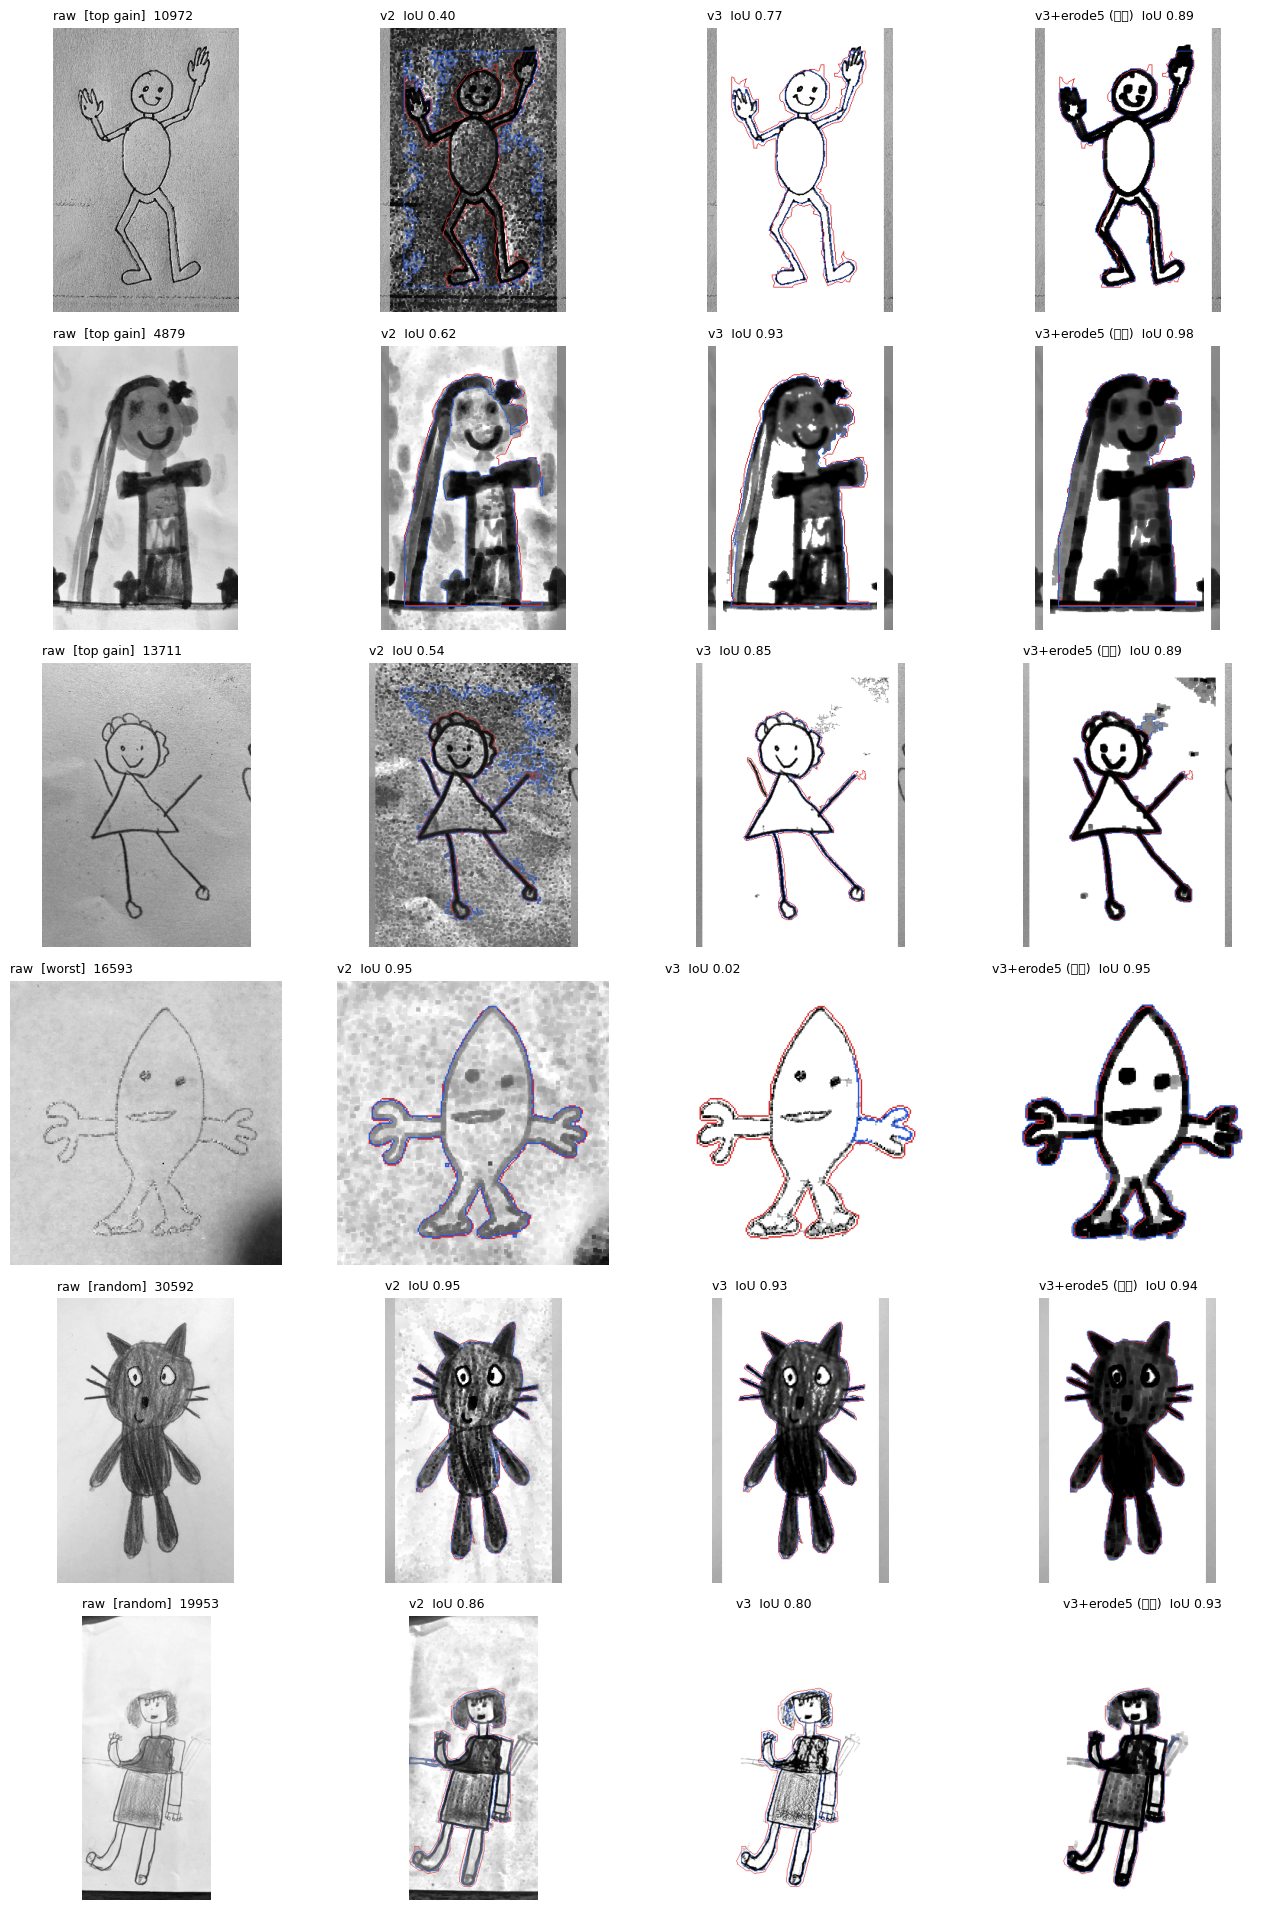

In [10]:
dd = (RES['v3'].iou - RES['v2'].iou).sort_values()
pick_ids = list(dd.index[-3:][::-1]) + list(dd.index[:1]) + list(np.random.default_rng(SEED).choice(dd.index, 2, replace=False))
tags = ['top gain'] * 3 + ['worst'] + ['random'] * 2


def contour_on(gimg, mask, color, th=1):
    rgb = cv2.cvtColor(gimg, cv2.COLOR_GRAY2RGB) if gimg.ndim == 2 else gimg
    cs, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(rgb, cs, -1, color, th)
    return rgb


fig, axs = plt.subplots(len(pick_ids), 4, figsize=(13.5, 3.2 * len(pick_ids)), facecolor='white')
for row, (iid, tg_) in zip(axs, zip(pick_ids, tags)):
    r = dev[dev.image_id == iid].iloc[0]
    g, gt = get(r)
    x, y, w, h = [int(round(v)) for v in r.bbox]
    pad = int(0.1 * max(w, h)); x0, y0, x1, y1 = max(0, x - pad), max(0, y - pad), x + w + pad, y + h + pad
    for ax, (ttl, steps) in zip(row[1:], [('v2', V2), ('v3', V3), ('v3+erode5 (대안)', ALT)]):
        out = pp.preprocess(g, r.bbox, mode=steps, margin=MARGIN)
        pred = pp.segment(out, r.bbox, 'otsu')
        vis = contour_on(out, gt, (220, 40, 40)); vis = contour_on(vis, pred, (40, 90, 220))
        ax.imshow(vis[y0:y1, x0:x1]); ax.set_title(f'{ttl}  IoU {RES[ttl].iou[iid]:.2f}', fontsize=9, loc='left'); ax.axis('off')
    row[0].imshow(g[y0:y1, x0:x1], cmap='gray'); row[0].set_title(f'raw  [{tg_}]  {iid}', fontsize=9, loc='left'); row[0].axis('off')
plt.tight_layout(); fig.savefig(os.path.join(OUT, 'v6_gallery.png'), dpi=120, facecolor='white'); plt.show()

(2) 전처리 결과만 비교. 원본 / v2 / v3 / v3+erode5, 그룹별 4장씩 12장.

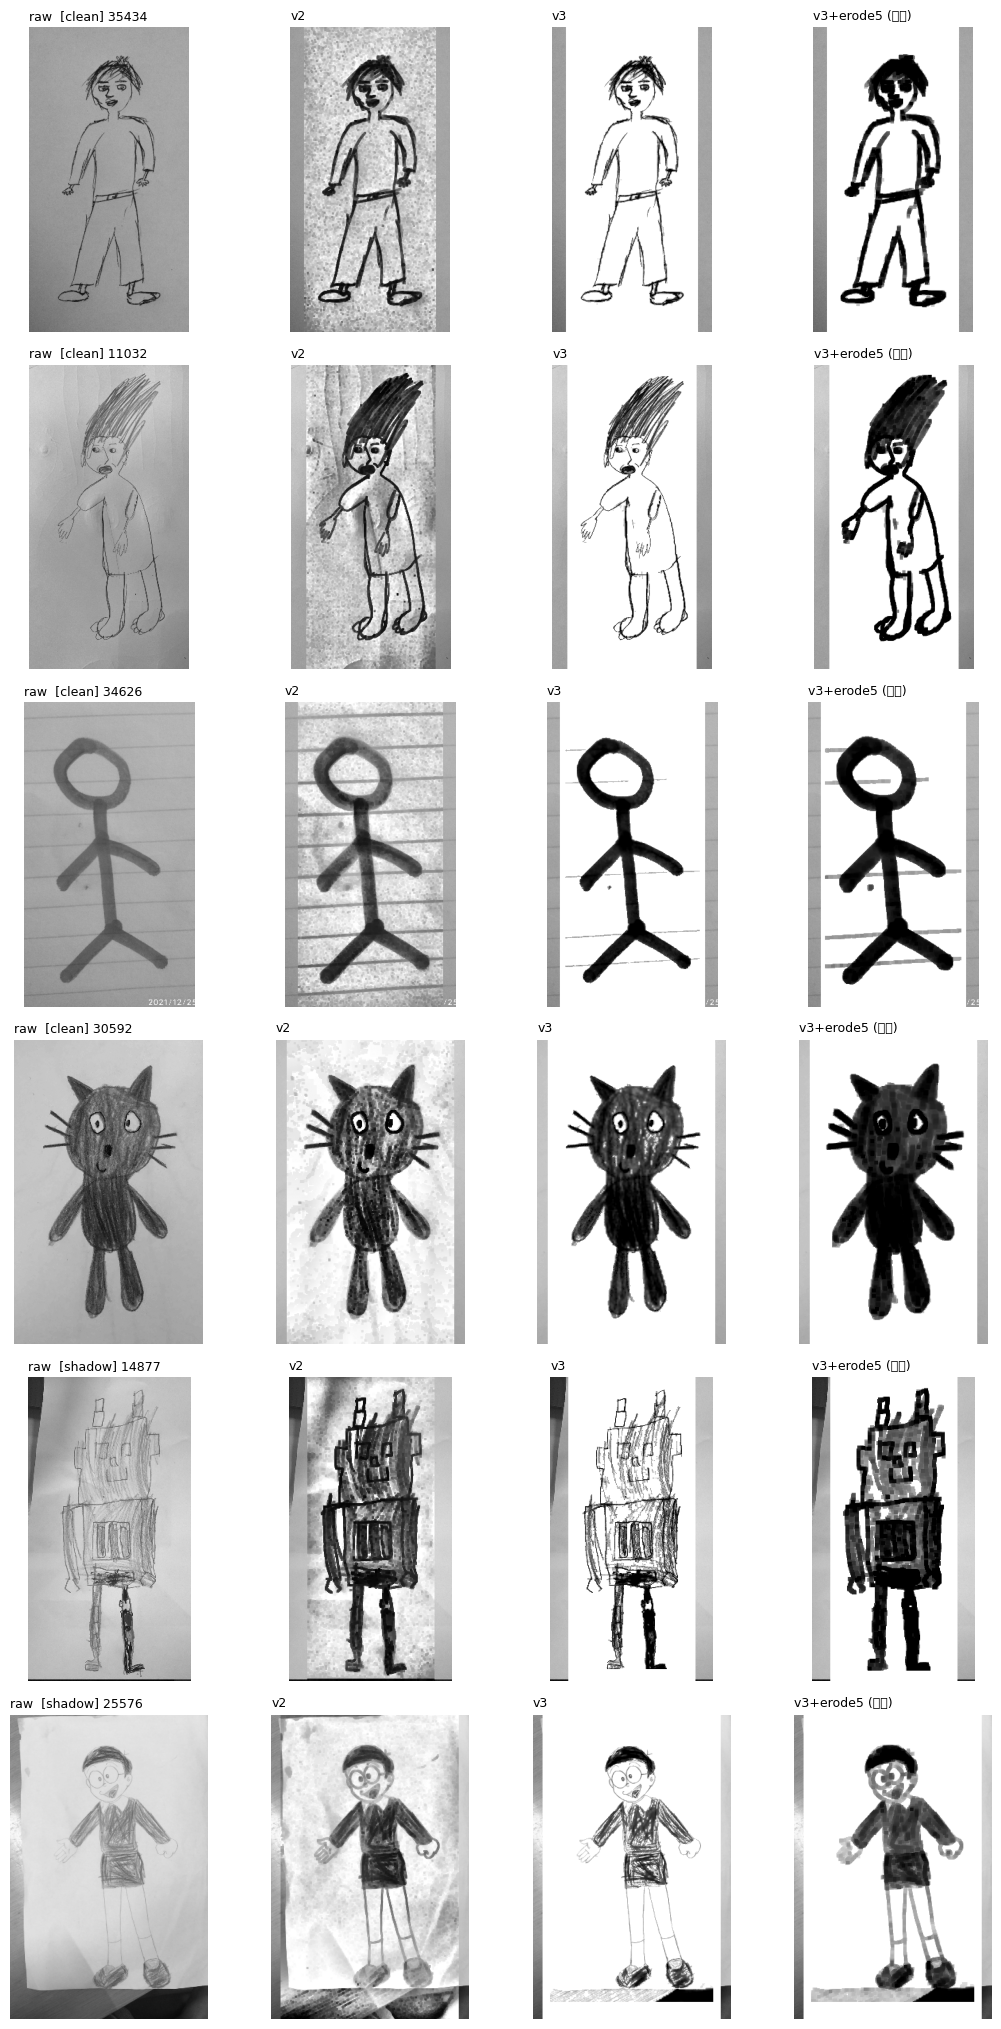

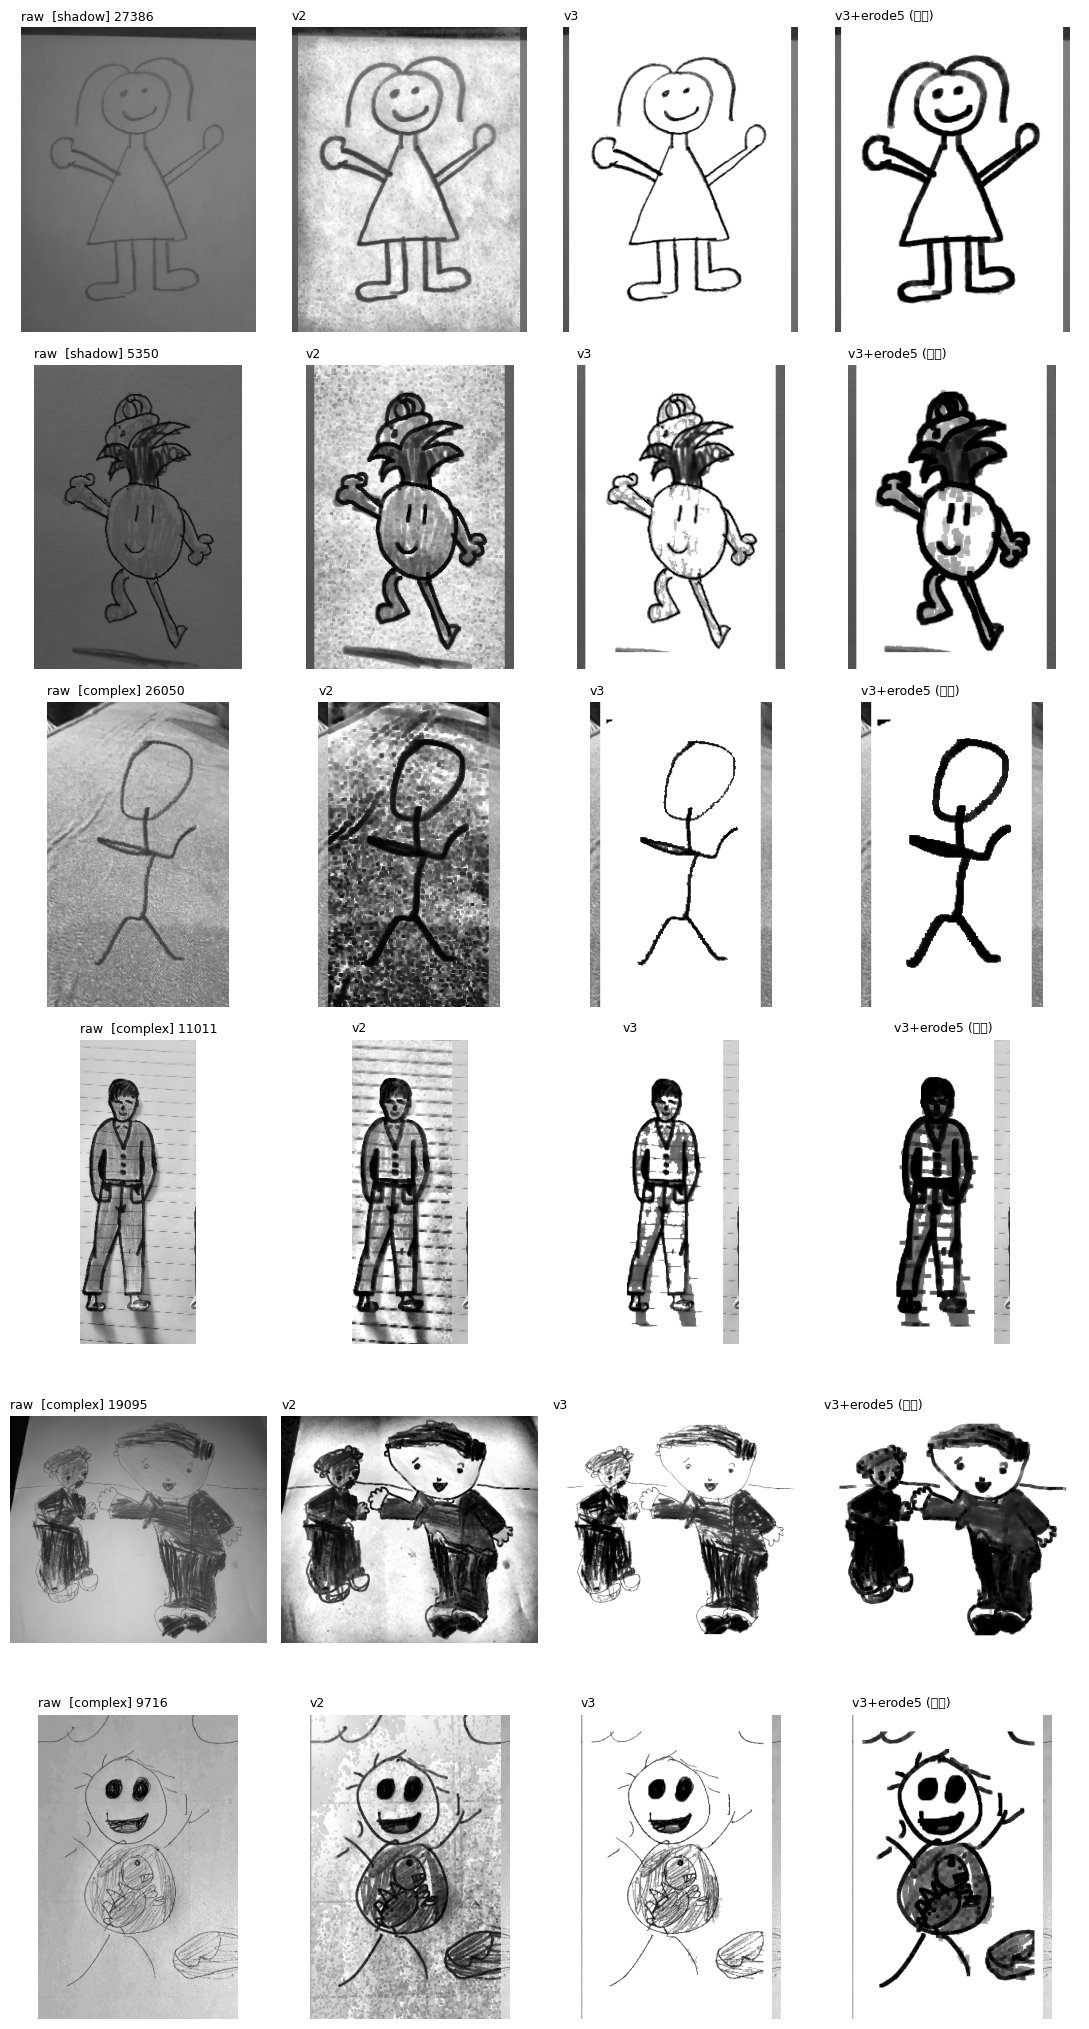

In [11]:
rng_ = np.random.default_rng(SEED + 1)
ids12 = [i for grp_ in ['clean', 'shadow', 'complex'] for i in rng_.choice(GRP[GRP == grp_].index, 4, replace=False)]
cols3 = [('raw', None), ('v2', V2), ('v3', V3), ('v3+erode5 (대안)', ALT)]
for pg in range(0, len(ids12), 6):
    ch = ids12[pg:pg + 6]
    fig, axs = plt.subplots(len(ch), 4, figsize=(11, 3.4 * len(ch)), facecolor='white', squeeze=False)
    for row, iid in zip(axs, ch):
        r = dev[dev.image_id == iid].iloc[0]; g, _ = get(r)
        x, y, w, h = [int(round(v)) for v in r.bbox]; pad = int(0.1 * max(w, h))
        x0, y0, x1, y1 = max(0, x - pad), max(0, y - pad), x + w + pad, y + h + pad
        for ax, (ttl, st) in zip(row, cols3):
            img = g if st is None else pp.preprocess(g, r.bbox, mode=st, margin=MARGIN)
            ax.imshow(img[y0:y1, x0:x1], cmap='gray', vmin=0, vmax=255); ax.axis('off')
            ax.set_title(f'{ttl}  [{r.group}] {iid}' if st is None else ttl, fontsize=9, loc='left')
    plt.tight_layout(); fig.savefig(os.path.join(OUT, f'v6_before_after_{pg // 6 + 1}.png'), dpi=110, facecolor='white'); plt.show()

## 9. 설정 고정
`mode='v3'`, `mode='v3_thick'`이 위에서 쓴 단계 목록과 똑같은 결과를 내는지 확인하고 설정을 json으로 저장함.

In [12]:
for r in dev.head(25).itertuples():
    g, _ = get(r)
    a = pp.preprocess(g, r.bbox, mode='v3', margin=MARGIN)
    b = pp.preprocess(g, r.bbox, mode=V3, margin=MARGIN)
    assert np.array_equal(a, b), f'mode v3 결과가 다름: {r.image_id}'
    a2 = pp.preprocess(g, r.bbox, mode='v3_thick', margin=MARGIN)
    b2 = pp.preprocess(g, r.bbox, mode=ALT, margin=MARGIN)
    assert np.array_equal(a2, b2), f'mode v3_thick 결과가 다름: {r.image_id}'

t = time.perf_counter()
for r in dev.head(40).itertuples():
    g, _ = get(r); pp.preprocess(g, r.bbox, mode='v3', margin=MARGIN)
ms = (time.perf_counter() - t) / 40 * 1000
v3s = RES['v3']
alt_s = RES['v3+erode5 (대안)']
FROZEN = {'name': 'v3', 'steps': ['tophat2(kernels=9/25/61/121, hysteresis, auto-bold, border 4%)', 'gate(bbox+3%)'],
          'alternative_undecided': {'name': 'v3_thick', 'extra_step': 'erode5(5x5)', 'dev_IoU': float(alt_s.iou.mean()), 'dev_fail': float((alt_s.iou < 0.2).mean())},
          'dev_IoU': float(v3s.iou.mean()), 'dev_fail': float((v3s.iou < 0.2).mean()), 'n_dev': int(len(dev)),
          'ms_per_image': round(ms, 1), 'MARGIN': MARGIN, 'seg': 'otsu',
          'note': 'erode5는 아직 정하지 않은 대안. 입력은 가로세로 500~600px 크롭 기준.'}
json.dump(FROZEN, open(os.path.join(OUT, 'v3_frozen.json'), 'w'), ensure_ascii=False, indent=2)
shutil.copy(os.path.abspath('preprocess.py'), os.path.join(BASE, 'preprocess.py'))
print(json.dumps(FROZEN, ensure_ascii=False, indent=1))

{
 "name": "v3",
 "steps": [
  "tophat2(kernels=9/25/61/121, hysteresis, auto-bold, border 4%)",
  "gate(bbox+3%)"
 ],
 "alternative_undecided": {
  "name": "v3_thick",
  "extra_step": "erode5(5x5)",
  "dev_IoU": 0.8329948446857054,
  "dev_fail": 0.00975609756097561
 },
 "dev_IoU": 0.6186234927192444,
 "dev_fail": 0.14634146341463414,
 "n_dev": 205,
 "ms_per_image": 43.0,
 "MARGIN": 0.1,
 "seg": "otsu",
 "note": "erode5는 아직 정하지 않은 대안. 입력은 가로세로 500~600px 크롭 기준."
}


## 10. test 평가
설정을 고정한 뒤 한 번만 실행함. 결과를 보고 설정을 바꾸면 안 됨. `FINAL = True`로 바꿔서 실행.

In [13]:
FINAL = False

if not FINAL:
    print('FINAL=False: test는 열지 않음')
else:
    assert os.path.exists(os.path.join(OUT, 'v3_frozen.json')), '9번 셀을 먼저 실행'
    TEST_SPECS = {                                    # 이름: (단계, 후처리 팽창 px)
        'raw':          ([], 0),
        'clahe(2,8)':   (['clahe'], 0),
        'v2':           (V2, 0),
        'v2+dil1':      (V2, 1),
        'v3':           (V3, 0),
        'v3+dil1':      (V3, 1),
        'v3+erode5':    (ALT, 0),
    }
    test = to_local(ok[ok.split == 'test'].reset_index(drop=True))
    tres = {n: run_spec(test, st, d) for n, (st, d) in TEST_SPECS.items()}
    tg = test.set_index('image_id')['group']
    ft_tab = summarize(tres, list(tres), tg.reindex(tres['raw'].index))
    ft_tab = ft_tab.rename(columns={'IoU': 'ALL'})[['clean', 'complex', 'shadow', 'ALL', 'fail<0.2', 'bf1']]
    display(ft_tab.round(3))
    for other in ['raw', 'clahe(2,8)', 'v2', 'v2+dil1', 'v3+erode5']:
        d = (tres['v3'].iou - tres[other].iou).values
        lo, hi = boot_ci(d)
        print(f'v3 - {other:12s} {d.mean():+.4f}  CI [{lo:+.3f}, {hi:+.3f}]   better {int((d > 0.02).sum())} / worse {int((d < -0.02).sum())}')
    ft_tab.round(4).to_csv(os.path.join(OUT, 'v3_test_table.csv'))
    pd.concat(tres, names=['spec']).reset_index(level=0).rename_axis('image_id').reset_index() \
        .to_csv(os.path.join(OUT, 'v3_test_per_image.csv'), index=False)
    print(f'test {len(test)}장')

FINAL=False: test는 열지 않음


## 부록

### 시도했다가 쓰지 않은 것 (dev)
- 순서 바꾸기(균일화 → nlm → 대비): 그늘 띠가 남고 가는 선이 약해짐
- 그림자 제거 방법 비교: closing 계열은 경계에 띠가 남고, 다항식 곡면은 그림자가 남고, Retinex는 회색으로 뜸. adaptive threshold는 칠한 부분에 구멍이 나고 격자나 테두리까지 잉크로 잡음. 타일별 Otsu는 잉크 없는 타일이 검게 됨
- tophat2에 blur를 섞기: blur5는 IoU 0.6602, blur5 + erode3는 0.7398
- 공책 줄 지우기(`suppress_lines`): 줄은 지워지지만 그림의 선도 끊김. 긴 직선 제거는 실제 사진에서 줄이 안 지워짐

### v3 결과 (dev 205장)
- v3 (tophat2 + gate): IoU 0.6186, 실패율 14.63%
- v3 + erode3: 0.7831 / 3.41%
- v3 + erode5 (대안): 0.8330 / 0.98%
- v2: 0.8202 / 0.98%

### 한계
- 선 굵기를 정해야 함 (위의 대안)
- 공책 줄과 격자는 그대로 남음 (14483, 7497, 5003)
- 아주 작고 연한 그림은 선을 놓침 (6677, 19885)
- 초점이 나간 사진은 흐린 채로 나옴
- gate는 bbox가 정확하다고 가정함. 검출기 bbox가 헐거우면 pad_frac을 키워야 함
- 커널이 픽셀 단위라 가로세로 500~600px 크롭 기준임. 더 큰 사진은 먼저 줄여야 함
- test는 v2로 한 번 열었음. v3 설정은 dev에서만 정함